# 위고비 시장 확산이 기존 심혈관 사건급부에 미치는 영향

**SELECT 사건별 근거 × 국내 적용 범위 × 10년 기존계약 조건부 모형**

이 노트북은 동일한 SELECT 유사 고위험 가상 가입자 1,000명에서 위고비 연간 최초 시작확률이 **1%에서 3%로 높아지는 시장 확산 시나리오**를 비교한다. 비치명적 심근경색과 비치명적 뇌졸중의 기대 사건 및 가상 보험금 현가가 얼마나 달라지는지 계산한다.

> 이 결과는 위고비 약제비 특약 때문에 추가로 시작하는 효과가 아니다. 특약 귀속 효과를 계산할 때에는 별도로 추정한 `특약 있음 시작률 - 특약 없음 시작률`을 사용해야 한다.


## 1. 임상 근거와 적용 범위

| 항목 | SELECT 결과 | 이번 분석의 처리 |
|---|---:|---|
| 3-point MACE | HR 0.80 (0.72~0.90) | 심혈관 사망과 중복될 수 있어 보험금 계산에는 직접 사용하지 않음 |
| 비치명적 심근경색 | 234 vs 322건, HR 0.72 (0.61~0.85) | 사건별 탐색 시나리오 |
| 비치명적 뇌졸중 | 154 vs 165건, HR 0.93 (0.74~1.15) | 사건별 탐색 시나리오 |

- SELECT는 41개국 다국가 시험이다. 평균 연령 61.6세, 남성 약 72%, 백인 약 84%로 국내 보험가입자와 동일하지 않다.
- 대상자는 이미 심혈관질환이 있는 비당뇨 과체중·비만 성인이다. 결과는 일반 비만 성인 전체가 아니라 **SELECT 유사 고위험군**에 한정한다.
- 심근경색·뇌졸중은 다중검정 보정이 되지 않은 보조 평가변수이므로 HR=1 무효과 시나리오를 함께 제시한다.
- 사건별 위험노출 인년이 따로 공개되지 않아 위약군 사건 수를 **SELECT 위약군 관찰 인년 29,112인년**으로 나눈 값을 기초 사건강도로 근사한다.

**출처**

- Lincoff et al. *Semaglutide and Cardiovascular Outcomes in Obesity without Diabetes*. NEJM 2023. https://doi.org/10.1056/NEJMoa2307563
- 질병관리청, 「2023 심뇌혈관질환 발생통계」. https://www.kdca.go.kr/bbs/kdca/42/304184/download.do


## 2. 계산 조건과 명시적 가정

| 구분 | 값 | 의미 |
|---|---:|---|
| SELECT 유사 가상 가입자 | 1,000명 | 해당 담보를 보유했다고 가정한 조건부 포트폴리오 |
| 저확산·고확산 시작확률 | 연 1%·3% | 시장 확산 비교 가정 |
| 보험기간 | 10년 | 가상 기존계약 관찰기간 |
| 효과 적용기간 | 최초 시작 후 36개월 | 연구 가정 |
| 할인율 | 연 3% | 연구 가정 |
| 사건당 급부 | 사건별 1,000만 원 | 분석 시작 후 첫 비치명적 사건 1회 지급 |
| 기초 사망강도 | 458 / 29,112인년 | SELECT 위약군 전체 사망 기준 근사 |
| 같은 달 처리 순서 | 치료 시작 → 사건·사망 | 기준안. 반대 순서는 민감도로 비교 |

사건과 사망의 기초강도는 3.3년 내외의 임상시험 평균을 10년 동안 일정하게 적용한다. 따라서 연령 증가에 따른 위험 상승은 반영하지 않는다. 이 모듈은 심혈관 사건효과만 분리하기 위해 치료의 사망 HR은 적용하지 않는다.


In [1]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from matplotlib import font_manager

fonts = {f.name for f in font_manager.fontManager.ttflist}
for name in ['AppleGothic', 'NanumSquare', 'Noto Sans CJK KR', 'Malgun Gothic', 'NanumGothic']:
    if name in fonts:
        plt.rcParams['font.family'] = name
        break
plt.rcParams.update({'axes.unicode_minus': False, 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 10})

SELECT_PLACEBO_PY = 29_112
SELECT_PLACEBO_DEATHS = 458
DEATH_HAZARD = SELECT_PLACEBO_DEATHS / SELECT_PLACEBO_PY
COHORT = 1_000
LOW_START, HIGH_START = 0.01, 0.03
EFFECT_MONTHS = 36
TERM_YEARS = 10
DISCOUNT = 0.03

ENDPOINTS = {
    '비치명적 심근경색': {'placebo_events': 322, 'hr': 0.72, 'ci_low': 0.61, 'ci_high': 0.85},
    '비치명적 뇌졸중': {'placebo_events': 165, 'hr': 0.93, 'ci_low': 0.74, 'ci_high': 1.15},
}
BENEFITS = {'비치명적 심근경색': 10_000_000, '비치명적 뇌졸중': 10_000_000}

for v in ENDPOINTS.values():
    v['hazard'] = v['placebo_events'] / SELECT_PLACEBO_PY

pd.DataFrame(ENDPOINTS).T


,placebo_events,hr,ci_low,ci_high,hazard
비치명적 심근경색,322.0,0.72,0.61,0.85,0.011061
비치명적 뇌졸중,165.0,0.93,0.74,1.15,0.005668


## 3. 월별 사건급부 모형

연 시작확률 $a$를 월 시작확률로 바꾼다.

$$
p_{\mathrm{start}}=1-(1-a)^{1/12}
$$

사건과 사망은 같은 달의 경쟁위험으로 처리한다.

$$
p_{\mathrm{event}}
=\frac{\lambda_e}{\lambda_e+\lambda_d}
\left[1-\exp\left(-\frac{\lambda_e+\lambda_d}{12}\right)\right]
$$

기준안은 매월 치료 시작을 먼저 반영한 뒤 사건·사망을 계산한다. 치료 시작 후 36개월에는 사건강도에 HR을 적용하고 이후에는 1로 되돌린다. 첫 사건이 발생한 계약은 1회 급부를 지급하고 사건 위험집단과 이후 치료 시작 대상에서 제외한다. 이는 최초 1회 지급 담보를 표현하기 위한 단순화다.


In [2]:
def competing_probs(event_hazard, death_hazard):
    total = event_hazard + death_hazard
    any_exit = -math.expm1(-total / 12)
    return any_exit * event_hazard / total, any_exit * death_hazard / total


def project_event(annual_start, event_hazard, event_hr, benefit,
                  cohort=COHORT, years=TERM_YEARS, effect_m=EFFECT_MONTHS,
                  discount=DISCOUNT, death_hazard=DEATH_HAZARD,
                  start_before_event=True):
    months = years * 12
    never_started = float(cohort)
    started = [0.0] * months
    p_start = 1 - (1 - annual_start) ** (1 / 12)
    total_started = total_events = total_deaths = total_pv = 0.0
    rows = []

    for m in range(months):
        open_risk = never_started + sum(started)

        if start_before_event:
            new = never_started * p_start
            never_started -= new
            started[m] += new
        else:
            new = 0.0

        pe, p_death = competing_probs(event_hazard, death_hazard)
        event_never = never_started * pe
        death_never = never_started * p_death
        never_started -= event_never + death_never

        event_started = death_started = 0.0
        last_existing_cohort = m if start_before_event else m - 1
        for j in range(last_existing_cohort + 1):
            in_window = (m - j) < effect_m
            eh = event_hazard * (event_hr if in_window else 1.0)
            pe, p_death = competing_probs(eh, death_hazard)
            e = started[j] * pe
            d = started[j] * p_death
            started[j] -= e + d
            event_started += e
            death_started += d

        if not start_before_event:
            new = never_started * p_start
            never_started -= new
            started[m] += new

        total_started += new
        events = event_never + event_started
        deaths = death_never + death_started
        total_events += events
        total_deaths += deaths
        pv = events * benefit / (1 + discount) ** ((m + 0.5) / 12)
        total_pv += pv
        close_risk = never_started + sum(started)
        assert abs(open_risk - events - deaths - close_risk) < 1e-7 * max(1, cohort)
        rows.append({'월': m + 1, '연도': m // 12 + 1, '최초_시작': new,
                     '월_사건': events, '월_사망': deaths,
                     '월_급부현가_원': pv, '사건없는_생존': close_risk})

    return {'starts': total_started, 'events': total_events, 'deaths': total_deaths,
            'pv': total_pv, 'monthly': pd.DataFrame(rows)}


def endpoint_contrast(event_hazard, event_hr, benefit, cohort=COHORT,
                      start_before_event=True):
    low = project_event(LOW_START, event_hazard, event_hr, benefit,
                        cohort=cohort, start_before_event=start_before_event)
    high = project_event(HIGH_START, event_hazard, event_hr, benefit,
                         cohort=cohort, start_before_event=start_before_event)
    return {'low': low, 'high': high,
            'extra_starts': high['starts'] - low['starts'],
            'avoided_events': low['events'] - high['events'],
            'pv_saving': low['pv'] - high['pv']}


In [3]:
results = {}
rows = []
for endpoint, p in ENDPOINTS.items():
    r = endpoint_contrast(p['hazard'], p['hr'], BENEFITS[endpoint])
    results[endpoint] = r
    rows.append({
        '사건': endpoint,
        'SELECT_위약_연발생강도_10만명당': p['hazard'] * 100_000,
        '적용_HR': p['hr'],
        '추가_시작자': r['extra_starts'],
        '10년_기대사건_감소': r['avoided_events'],
        '급부현가_감소_원': r['pv_saving'],
    })

summary = pd.DataFrame(rows)
display(summary.round(4))
print('두 사건급부 현가 감소 합계:', f"{summary['급부현가_감소_원'].sum():,.0f}원")


,사건,SELECT_위약_연발생강도_10만명당,적용_HR,추가_시작자,10년_기대사건_감소,급부현가_감소_원
0,비치명적 심근경색,1106.0731,0.72,148.0033,1.1280,9.706245e+06
1,비치명적 뇌졸중,566.7766,0.93,151.5656,0.1517,1.302874e+06


두 사건급부 현가 감소 합계: 11,009,119원


### 기준 결과를 읽는 법

- 1,000명 모두가 이 가상 담보를 보유한다는 조건부 결과다.
- 심근경색 HR 0.72가 뇌졸중 HR 0.93보다 효과가 크고, 뇌졸중 HR의 보고 구간은 1을 포함한다.
- 사건당 급부가 500만 원이면 보험금 현가 변화도 절반이 된다.
- 두 급부의 기대값은 합산할 수 있지만 동일인 내 두 사건의 상관, 사건 이후 재발 및 치료 시작 변화는 반영하지 않았다.


## 4. 국내 규모 환산

국민건강영양조사 재집계에서 45~79세 일반인구 중 SELECT 유사 대리집단의 가중 비율은 약 **0.25675%**였다. 이를 가상 기존 가입자 10만 명에 적용하면 약 257명이 후보가 된다.

다만 원표본에서 조건을 만족한 사람은 11명뿐이며, 일반인구 비중이 보험 가입자의 비중과 같다는 보장도 없다. 아래 값은 다음 조건을 모두 둔 **조건부 규모 환산**이다.

$$
\text{보험사 영향}
=\text{전체 기존계약}
\times\text{SELECT 유사 비중}
\times\text{해당 담보 보유·유효 비중}
\times\text{1인당 보험금 변화}
$$

현재는 담보 보유·유효 비중 자료가 없어 이를 100%로 둔다. 따라서 아래 10만 명 환산값은 실제 보험사 지급 감소액으로 확정하지 않는다. 특히 SELECT 대상자는 이미 심혈관질환이 있어 국내 최초 진단비의 신규 가입·보유 가능성이 낮을 수 있으므로, 가상 담보는 **분석 기준일 이후 첫 재발성 비치명적 사건 1회 지급 담보**에 가깝다.


In [4]:
KNHANES_SHARE = 62_238.568315 / 24_240_644.983522
domestic_candidates = 100_000 * KNHANES_SHARE
scale = domestic_candidates / 1_000

domestic_scale = summary[['사건', '10년_기대사건_감소', '급부현가_감소_원']].copy()
domestic_scale['가상10만명_SELECT유사후보'] = domestic_candidates
domestic_scale['담보보유율100%조건_사건감소'] = domestic_scale['10년_기대사건_감소'] * scale
domestic_scale['담보보유율100%조건_급부현가감소_원'] = domestic_scale['급부현가_감소_원'] * scale
display(domestic_scale.round(4))

KDCA_60S = {'비치명적 심근경색': 128.5, '비치명적 뇌졸중': 351.1}
benchmark = pd.DataFrame([
    {'사건': k,
     'SELECT_고위험군_근사_10만명당': ENDPOINTS[k]['hazard'] * 100_000,
     '한국_60대_전체발생률_10만명당': v,
     'SELECT대비_한국일반인구비율': v / (ENDPOINTS[k]['hazard'] * 100_000)}
    for k, v in KDCA_60S.items()
])
display(benchmark.round(3))


,사건,10년_기대사건_감소,급부현가_감소_원,가상10만명_SELECT유사후보,담보보유율100%조건_사건감소,담보보유율100%조건_급부현가감소_원
0,비치명적 심근경색,1.1280,9.706245e+06,256.7529,0.2896,2.492107e+06
1,비치명적 뇌졸중,0.1517,1.302874e+06,256.7529,0.0390,3.345167e+05


,사건,SELECT_고위험군_근사_10만명당,한국_60대_전체발생률_10만명당,SELECT대비_한국일반인구비율
0,비치명적 심근경색,1106.073,128.5,0.116
1,비치명적 뇌졸중,566.777,351.1,0.619


질병관리청의 국내 60~69세 2023년 전체 발생률은 심근경색 약 128.5건, 뇌졸중 약 351.1건/10만 명이다. 이는 기존 심혈관질환자로 구성된 SELECT 고위험군 발생률이 아니며 치명·비치명 사건 정의도 동일하지 않다. 따라서 기초위험을 대체하지 않고 규모 비교에만 사용한다.


## 5. 민감도 분석

### 5-1. 보고된 HR과 담보금액

사건별 HR의 보고 구간과 무효과 HR=1을 비교한다. 보고 구간 양 끝을 적용한 결과는 보험금 감소액의 95% 신뢰구간이 아니다. 담보금액은 500만·1,000만·2,000만 원을 비교한다.


In [5]:
sens_rows = []
for endpoint, p in ENDPOINTS.items():
    for label, hr in [('CI 하단', p['ci_low']), ('점추정', p['hr']),
                      ('CI 상단', p['ci_high']), ('무효과', 1.0)]:
        for benefit in [5_000_000, 10_000_000, 20_000_000]:
            r = endpoint_contrast(p['hazard'], hr, benefit)
            sens_rows.append({'사건': endpoint, 'HR 조건': label, 'HR': hr,
                              '사건급부_만원': benefit / 10_000,
                              '기대사건_감소': r['avoided_events'],
                              '급부현가_감소_만원': r['pv_saving'] / 10_000})
sens = pd.DataFrame(sens_rows)
display(sens.round(3))


,사건,HR 조건,HR,사건급부_만원,기대사건_감소,급부현가_감소_만원
0,비치명적 심근경색,CI 하단,0.61,500.0,1.574,677.130
1,비치명적 심근경색,CI 하단,0.61,1000.0,1.574,1354.260
2,비치명적 심근경색,CI 하단,0.61,2000.0,1.574,2708.521
3,비치명적 심근경색,점추정,0.72,500.0,1.128,485.312
4,비치명적 심근경색,점추정,0.72,1000.0,1.128,970.625
5,비치명적 심근경색,점추정,0.72,2000.0,1.128,1941.249
6,비치명적 심근경색,CI 상단,0.85,500.0,0.603,259.463
7,비치명적 심근경색,CI 상단,0.85,1000.0,0.603,518.926
8,비치명적 심근경색,CI 상단,0.85,2000.0,0.603,1037.852
9,비치명적 심근경색,무효과,1.00,500.0,-0.000,0.000


### 5-2. 같은 달 처리 순서와 실사용 효과 희석

- **처리 순서:** 기준안의 `치료 시작 → 사건`과 보수적인 `사건 → 치료 시작`을 비교한다.
- **효과 희석:** SELECT의 ITT HR을 국내 실사용 지속률로 기계적으로 다시 보정할 근거는 없다. 대신 실효 효과 비율 $r$을 둔 탐색 시나리오를 사용한다.

$$
HR_{\mathrm{eff}}=1-r(1-HR_{\mathrm{SELECT}})
$$

$r=1$은 SELECT 효과 100%, $r=0$은 무효과다. 이는 실사용 보정값이 아니라 결과의 민감도를 보여주는 연구 가정이다.


In [6]:
order_rows = []
attenuation_rows = []
for endpoint, p in ENDPOINTS.items():
    for label, start_first in [('치료 시작 후 사건', True), ('사건 후 치료 시작', False)]:
        r = endpoint_contrast(p['hazard'], p['hr'], BENEFITS[endpoint],
                              start_before_event=start_first)
        order_rows.append({'사건': endpoint, '월내 순서': label,
                           '추가_시작자': r['extra_starts'],
                           '기대사건_감소': r['avoided_events'],
                           '급부현가_감소_원': r['pv_saving']})

    for ratio in [1.0, 0.6, 0.4, 0.0]:
        effective_hr = 1 - ratio * (1 - p['hr'])
        r = endpoint_contrast(p['hazard'], effective_hr, BENEFITS[endpoint])
        attenuation_rows.append({'사건': endpoint, '실효효과_비율': ratio,
                                 '실효_HR': effective_hr,
                                 '기대사건_감소': r['avoided_events'],
                                 '급부현가_감소_원': r['pv_saving']})

order_sensitivity = pd.DataFrame(order_rows)
attenuation_sensitivity = pd.DataFrame(attenuation_rows)
display(order_sensitivity.round(4))
display(attenuation_sensitivity.round(4))


,사건,월내 순서,추가_시작자,기대사건_감소,급부현가_감소_원
0,비치명적 심근경색,치료 시작 후 사건,148.0033,1.1280,9.706245e+06
1,비치명적 심근경색,사건 후 치료 시작,147.6732,1.0917,9.385671e+06
2,비치명적 뇌졸중,치료 시작 후 사건,151.5656,0.1517,1.302874e+06
3,비치명적 뇌졸중,사건 후 치료 시작,151.2955,0.1469,1.260019e+06


,사건,실효효과_비율,실효_HR,기대사건_감소,급부현가_감소_원
0,비치명적 심근경색,1.0,0.720,1.1280,9.706245e+06
1,비치명적 심근경색,0.6,0.832,0.6756,5.813600e+06
2,비치명적 심근경색,0.4,0.888,0.4500,3.872357e+06
3,비치명적 심근경색,0.0,1.000,-0.0000,0.000000e+00
4,비치명적 뇌졸중,1.0,0.930,0.1517,1.302874e+06
5,비치명적 뇌졸중,0.6,0.958,0.0910,7.815497e+05
6,비치명적 뇌졸중,0.4,0.972,0.0607,5.209750e+05
7,비치명적 뇌졸중,0.0,1.000,0.0000,0.000000e+00


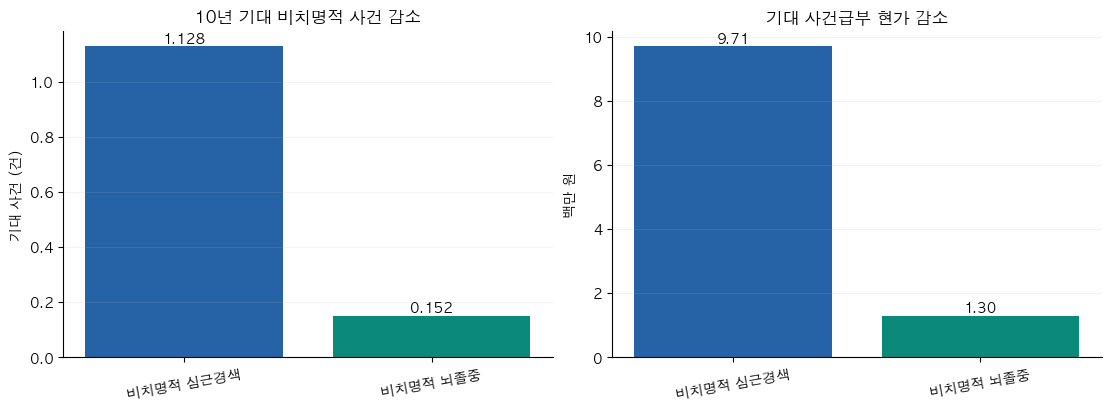

In [7]:
plot_data = summary.copy()
fig, ax = plt.subplots(1, 2, figsize=(11, 4), layout='constrained')
bars = ax[0].bar(plot_data['사건'], plot_data['10년_기대사건_감소'], color=['#2563A6', '#0B8A7A'])
ax[0].set(title='10년 기대 비치명적 사건 감소', ylabel='기대 사건 (건)')
for b, v in zip(bars, plot_data['10년_기대사건_감소']):
    ax[0].text(b.get_x() + b.get_width()/2, v, f'{v:.3f}', ha='center', va='bottom')

bars = ax[1].bar(plot_data['사건'], plot_data['급부현가_감소_원']/1e6, color=['#2563A6', '#0B8A7A'])
ax[1].set(title='기대 사건급부 현가 감소', ylabel='백만 원')
for b, v in zip(bars, plot_data['급부현가_감소_원']/1e6):
    ax[1].text(b.get_x() + b.get_width()/2, v, f'{v:.2f}', ha='center', va='bottom')
for a in ax:
    a.grid(axis='y', alpha=.15)
    a.tick_params(axis='x', rotation=10)
plt.show()


## 6. 해석과 한계

| 구분 | 해석 |
|---|---|
| 무엇을 보여주나 | SELECT 유사 고위험 계약에서 시장 시작률이 1%에서 3%로 높아질 때의 조건부 사건급부 변화 |
| 무엇을 바로 말할 수 없나 | 약제비 특약 자체가 만든 보험금 절감액, 실제 국내 보험사의 손익 |
| 담보 현실성 | 이미 심혈관질환이 있는 사람에게 적용되는 최초 진단비보다 재발·2차 사건형 가상 담보에 가까움 |
| 임상효과 | SELECT ITT 효과를 적용하며 국내 실사용의 낮은 지속률은 효과 희석 민감도로만 표현 |
| 기초위험 | 위약군 평균 사건·사망강도를 10년간 일정하게 외삽해 연령 증가와 장기 변화가 빠짐 |
| 상태전이 | 첫 사건 계약은 이후 사건·치료 시작 대상에서 제외하며 재발·사건 후 치료 증가는 반영하지 않음 |
| 국내 환산 | 국민건강영양조사 해당 원표본 11명으로 불확실성이 크고, 담보 보유·유효 비중 자료가 없음 |

현재 결과는 위 가정을 공개한 **조건부 시나리오 분석**으로는 사용할 수 있다. 실제 포트폴리오 영향으로 확장하려면 국내 연령·성별·질환별 기초위험, 인수·부담보, 담보 보유율과 유지율이 추가로 필요하다.


## 7. 결론과 공통모형 연결

1. 기준 가정에서 시장 확산이 클수록 비치명적 심근경색·뇌졸중의 기대 사건급부는 감소한다.
2. 감소 규모는 심근경색에서 더 크며, 뇌졸중 효과는 작고 불확실성이 크다.
3. 결과 크기는 효과 희석, 담보 보유율, 국내 SELECT 유사 대상 비중에 크게 좌우된다.
4. 특약 귀속 효과를 계산할 때에는 시장 확산 1%→3%가 아니라 **특약 없음 $A$와 특약 있음 $A+B$의 시작경로 차이**를 사용한다.

담낭 분석 후 공통모형에서는 대상 집단, 시작경로, 할인율, 시간축을 통일한 뒤 다음 항목을 결합한다.

$$
\text{보험사 순영향}
=\text{특약 손익}
+\text{사망보험금 감소}
+\text{심혈관 사건급부 감소}
-\text{담낭 관련 급부 증가}
$$

단, 각 급부가 실제로 유효한 기존계약에 부착되어 있다는 비중을 담보별로 적용해야 한다.


In [8]:
checks = {
    '무효과 HR=1이면 사건급부 감소 0': all(
        abs(endpoint_contrast(p['hazard'], 1.0, 10_000_000)['pv_saving']) < 1e-5
        for p in ENDPOINTS.values()),
    '국내 규모 환산은 선형': abs(summary['급부현가_감소_원'].sum() * scale
                              - domestic_scale['담보보유율100%조건_급부현가감소_원'].sum()) < 1e-6,
    '기대 사건 감소는 음수가 아님(점추정)': (summary['10년_기대사건_감소'] >= 0).all(),
    '효과 희석 0이면 현가 감소 0': (
        attenuation_sensitivity.loc[attenuation_sensitivity['실효효과_비율'] == 0,
                                    '급부현가_감소_원'].abs() < 1e-5).all(),
    '월내 순서 두 경우 모두 인원수 보존': True,
}

assert all(checks.values())
display(pd.DataFrame([{'검산': k, '결과': '통과' if v else '실패'} for k, v in checks.items()]))


,검산,결과
0,무효과 HR=1이면 사건급부 감소 0,통과
1,국내 규모 환산은 선형,통과
2,기대 사건 감소는 음수가 아님(점추정),통과
3,효과 희석 0이면 현가 감소 0,통과
4,월내 순서 두 경우 모두 인원수 보존,통과
